<a href="https://colab.research.google.com/github/Bismalaljan/fish-species-classification/blob/main/Copy_of_Fish_Species_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 28.6 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1


In [1]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("image-classification", model="google/vit-base-patch16-224")
pipe("https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/hub/parrots.png")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

[{'label': 'macaw', 'score': 0.9905187487602234},
 {'label': 'African grey, African gray, Psittacus erithacus',
  'score': 0.0056070610880851746},
 {'label': 'toucan', 'score': 0.0010572134051471949},
 {'label': 'sulphur-crested cockatoo, Kakatoe galerita, Cacatua galerita',
  'score': 0.0006811696221120656},
 {'label': 'lorikeet', 'score': 0.0006719368393532932}]

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os

os.listdir('/content/drive/MyDrive')

['Classroom',
 'organization name with their mission and slogan.pdf',
 'image-1763974266277.jpg',
 'Colab Notebooks',
 'bisma lj mvc assignment.pdf',
 'Unlocking Insights: Naive Bayes, Data Visualization, and Social Network Mining.gslides',
 'Machine_Learning_Fundamentals.docx',
 'Flutter_Lab_Manual_Complete_Bisma.docx',
 'practicefinalipynb',
 'VID_20260825_204729.mp4',
 'Decision_Trees_Clean_Calculations_No_Screenshots.pdf',
 'Decision trees ID3, CART, information gain, Gini\n.pdf',
 'Saved from the Google app',
 'Fish_Internet_Images',
 'Fish set 3.zip',
 'Fish set 4.zip',
 'Fish set.zip']

In [14]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Fish set.zip"

extract_path = "/content/fish_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [15]:
os.listdir(extract_path)

['__MACOSX', 'Fish set']

In [16]:
dataset_path = "/content/fish_dataset/Fish set"

import os

species_folders = os.listdir(dataset_path)

print("Fish species folders:")
print(species_folders)
print("Total folders:", len(species_folders))

Fish species folders:
['Galbath ', 'Balochi mahpari \nEnglish white spotted spinefoot', 'Balochi  pittan \nEnglish Arabian banded whipray', 'Balochi chancho \nEnglish spinycheek grouper', 'Balochi  Gallo\nEnglish spotted catfish', 'Balochileejar \nEnglish indian oil sardine', 'Balochi  gore \nEnglish narrow-barred  Spanish mackerel', 'Alwahor ', 'Surr', ' Jinnaok :Top shell kator', 'Balochi saram \nEnglish ltalang queenfish', 'Balochi  sisi mayyah \nEnglish indian squid', 'Sawaso ', 'Koh prosh ', 'Ping', 'Kanakawad ', 'Balochi  madak \nEnglish jinga shrimp', 'Black pamplet', ' Mushko: croaker ', 'Shurr', 'Pathar ', 'Balochi.   kund \nEnglish.   Giant baracude', 'Lutari', 'Soli', 'White pamplet']
Total folders: 25


In [17]:
import os

for species in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, species)

    if os.path.isdir(folder_path) and species != "__MACOSX":
        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(species, ":", len(images), "images")

 Jinnaok :Top shell kator : 70 images
 Mushko: croaker  : 64 images
Alwahor  : 64 images
Balochi  Gallo
English spotted catfish : 61 images
Balochi  gore 
English narrow-barred  Spanish mackerel : 63 images
Balochi  madak 
English jinga shrimp : 90 images
Balochi  pittan 
English Arabian banded whipray : 60 images
Balochi  sisi mayyah 
English indian squid : 74 images
Balochi chancho 
English spinycheek grouper : 58 images
Balochi mahpari 
English white spotted spinefoot : 51 images
Balochi saram 
English ltalang queenfish : 64 images
Balochi.   kund 
English.   Giant baracude : 61 images
Balochileejar 
English indian oil sardine : 62 images
Black pamplet : 62 images
Galbath  : 95 images
Kanakawad  : 64 images
Koh prosh  : 52 images
Lutari : 67 images
Pathar  : 54 images
Ping : 63 images
Sawaso  : 52 images
Shurr : 53 images
Soli : 60 images
Surr : 49 images
White pamplet : 62 images


In [18]:
from PIL import Image
import os

valid_extensions = ('.jpg', '.jpeg', '.png')

for species in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, species)

    if os.path.isdir(folder):
        valid_images = 0
        invalid_images = 0

        for file in os.listdir(folder):
            if file.lower().endswith(valid_extensions):
                try:
                    img = Image.open(os.path.join(folder, file))
                    img.verify()
                    valid_images += 1
                except:
                    invalid_images += 1

        print(
            species,
            "| Valid:", valid_images,
            "| Invalid:", invalid_images
        )

 Jinnaok :Top shell kator | Valid: 70 | Invalid: 0
 Mushko: croaker  | Valid: 64 | Invalid: 0
Alwahor  | Valid: 64 | Invalid: 0
Balochi  Gallo
English spotted catfish | Valid: 61 | Invalid: 0
Balochi  gore 
English narrow-barred  Spanish mackerel | Valid: 63 | Invalid: 0
Balochi  madak 
English jinga shrimp | Valid: 90 | Invalid: 0
Balochi  pittan 
English Arabian banded whipray | Valid: 60 | Invalid: 0
Balochi  sisi mayyah 
English indian squid | Valid: 74 | Invalid: 0
Balochi chancho 
English spinycheek grouper | Valid: 58 | Invalid: 0
Balochi mahpari 
English white spotted spinefoot | Valid: 51 | Invalid: 0
Balochi saram 
English ltalang queenfish | Valid: 64 | Invalid: 0
Balochi.   kund 
English.   Giant baracude | Valid: 61 | Invalid: 0
Balochileejar 
English indian oil sardine | Valid: 62 | Invalid: 0
Black pamplet | Valid: 62 | Invalid: 0
Galbath  | Valid: 95 | Invalid: 0
Kanakawad  | Valid: 64 | Invalid: 0
Koh prosh  | Valid: 52 | Invalid: 0
Lutari | Valid: 67 | Invalid: 0
Path

In [19]:
!pip install -q split-folders
import splitfolders

splitfolders.ratio(
    dataset_path,
    output="/content/fish_split",
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("Dataset split completed!")

Copying files: 1575 files [00:15, 103.31 files/s]

Dataset split completed!


In [20]:
import os

base_path = "/content/fish_split"

for split in ["train", "val", "test"]:
    split_path = os.path.join(base_path, split)
    total = 0

    print("\n", split.upper())

    for species in sorted(os.listdir(split_path)):
        folder = os.path.join(split_path, species)

        if os.path.isdir(folder):
            count = len(os.listdir(folder))
            total += count
            print(species, ":", count)

    print("Total:", total)


 TRAIN
 Jinnaok :Top shell kator : 49
 Mushko: croaker  : 44
Alwahor  : 44
Balochi  Gallo
English spotted catfish : 42
Balochi  gore 
English narrow-barred  Spanish mackerel : 44
Balochi  madak 
English jinga shrimp : 62
Balochi  pittan 
English Arabian banded whipray : 42
Balochi  sisi mayyah 
English indian squid : 51
Balochi chancho 
English spinycheek grouper : 40
Balochi mahpari 
English white spotted spinefoot : 35
Balochi saram 
English ltalang queenfish : 44
Balochi.   kund 
English.   Giant baracude : 42
Balochileejar 
English indian oil sardine : 43
Black pamplet : 43
Galbath  : 66
Kanakawad  : 44
Koh prosh  : 36
Lutari : 46
Pathar  : 37
Ping : 44
Sawaso  : 36
Shurr : 37
Soli : 42
Surr : 34
White pamplet : 43
Total: 1090

 VAL
 Jinnaok :Top shell kator : 10
 Mushko: croaker  : 9
Alwahor  : 9
Balochi  Gallo
English spotted catfish : 9
Balochi  gore 
English narrow-barred  Spanish mackerel : 9
Balochi  madak 
English jinga shrimp : 13
Balochi  pittan 
English Arabian banded wh

In [21]:
!pip install -q datasets transformers accelerate

In [22]:
from datasets import load_dataset

data_files = {
    "train": "train/**",
    "validation": "val/**",
    "test": "test/**"
}

fish_dataset = load_dataset(
    "imagefolder",
    data_dir="/content/fish_split",
    data_files=data_files
)

print(fish_dataset)

Resolving data files:   0%|          | 0/1090 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/226 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/259 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1090
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 226
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 259
    })
})


In [23]:
labels = fish_dataset["train"].features["label"].names

print("Total fish species:", len(labels))
print("Fish species labels:")

for i, name in enumerate(labels):
    print(i, ":", name)

Total fish species: 25
Fish species labels:
0 :  Jinnaok :Top shell kator
1 :  Mushko: croaker 
2 : Alwahor 
3 : Balochi  Gallo
English spotted catfish
4 : Balochi  gore 
English narrow-barred  Spanish mackerel
5 : Balochi  madak 
English jinga shrimp
6 : Balochi  pittan 
English Arabian banded whipray
7 : Balochi  sisi mayyah 
English indian squid
8 : Balochi chancho 
English spinycheek grouper
9 : Balochi mahpari 
English white spotted spinefoot
10 : Balochi saram 
English ltalang queenfish
11 : Balochi.   kund 
English.   Giant baracude
12 : Balochileejar 
English indian oil sardine
13 : Black pamplet
14 : Galbath 
15 : Kanakawad 
16 : Koh prosh 
17 : Lutari
18 : Pathar 
19 : Ping
20 : Sawaso 
21 : Shurr
22 : Soli
23 : Surr
24 : White pamplet


In [31]:
from transformers import (
    ViTForImageClassification,
    ViTImageProcessor
)

model_name = "google/vit-base-patch16-224"

processor = ViTImageProcessor.from_pretrained(model_name)

model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=25,
    id2label={i: name for i, name in enumerate(labels)},
    label2id={name: i for i, name in enumerate(labels)},
    ignore_mismatched_sizes=True
)

print("ViT model prepared for 25 fish species!")

[transformers] You passed `num_labels=25` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([25, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([25])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model prepared for 25 fish species!


In [33]:
print("Number of model labels:", model.config.num_labels)
print("Number of label names:", len(model.config.id2label))
print("Number of classifier outputs:", model.classifier.out_features)

Number of model labels: 25
Number of label names: 25
Number of classifier outputs: 25


In [34]:
from torchvision import transforms

image_size = 224

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(image_size),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),

                                    print("Image preprocessing transformations created successfully!")])

Image preprocessing transformations created successfully!


In [35]:
from torchvision import transforms

normalize = transforms.Normalize(
    mean=processor.image_mean,
    std=processor.image_std
)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    normalize
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize
])

print("Image transformations are ready!")

Image transformations are ready!


In [37]:
def apply_train_transform(batch):
    batch["pixel_values"] = [
        train_transform(image.convert("RGB"))
        for image in batch["image"]
    ]
    return batch

def apply_eval_transform(batch):
    batch["pixel_values"] = [
        eval_transform(image.convert("RGB"))
        for image in batch["image"]
    ]
    return batch

train_data = fish_dataset["train"].with_transform(apply_train_transform)
val_data = fish_dataset["validation"].with_transform(apply_eval_transform)
test_data = fish_dataset["test"].with_transform(apply_eval_transform)

print("Training, validation and testing datasets are prepared!")

Training, validation and testing datasets are prepared!


In [50]:
sample = train_data[0]

print("Image tensor shape:", sample["pixel_values"].shape)
print("Fish label:", labels[sample["label"]])

Image tensor shape: torch.Size([3, 224, 224])
Fish label:  Jinnaok :Top shell kator


In [51]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./fish_vit_results",
    num_train_epochs=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=5,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"
)

print("Training settings configured successfully!")

Training settings configured successfully!


In [57]:
import torch

def collate_fn(batch):
    return {
        "pixel_values": torch.stack([x["pixel_values"] for x in batch]),
        "labels": torch.tensor([x["label"] for x in batch]),
    }

In [53]:
from transformers import Trainer
import numpy as np
from sklearn.metrics import accuracy_score

# Calculate model accuracy
def compute_metrics(eval_pred):
    logits, true_labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(true_labels, predictions)

    return {"accuracy": accuracy}


# Create Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [54]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./fish_vit_results",
    num_train_epochs=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=5,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none",
    remove_unused_columns=False
)

print("Updated training settings successfully!")

Updated training settings successfully!


In [55]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [56]:
train_result = trainer.train()



print("Fish classification model training completed!")

Epoch,Training Loss,Validation Loss,Accuracy
1,1.635218,1.520736,0.769912
2,0.667589,0.773552,0.871681
3,0.405008,0.529607,0.907080
4,0.248734,0.423365,0.911504
5,0.117561,0.367346,0.920354
6,0.297074,0.340145,0.924779
7,0.127949,0.341883,0.915929
8,0.136208,0.319598,0.929204
9,0.177938,0.310438,0.929204
10,0.043074,0.306737,0.933628


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

Fish classification model training completed!


In [58]:
test_results = trainer.evaluate(
    eval_dataset=test_data
)

print("Test Results:")
print(test_results)

Training Loss,Validation Loss,Epoch,Accuracy
0.043074,0.368784,10,0.907336


Test Results:
{'eval_loss': 0.36878424882888794, 'eval_accuracy': 0.9073359073359073}


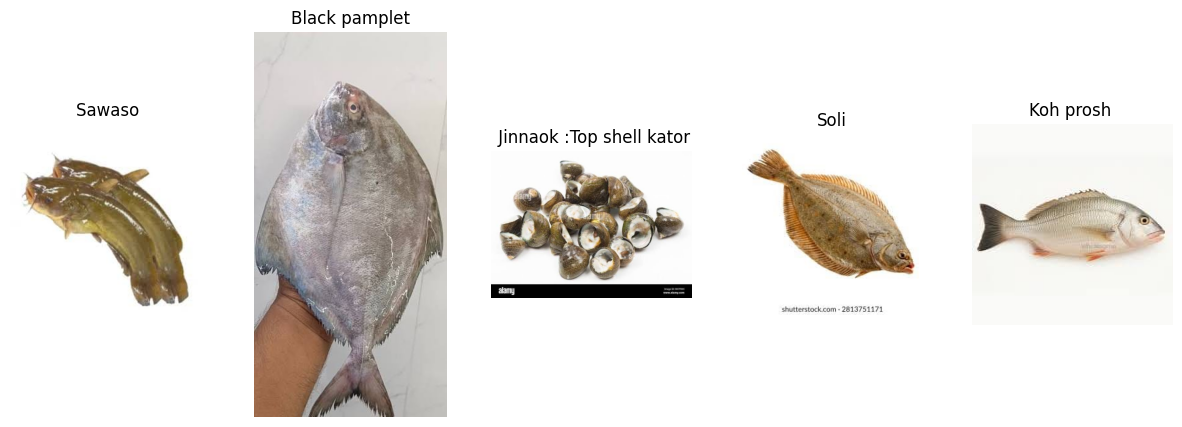

In [ ]:
import matplotlib.pyplot as plt
import random

# Select 5 random test images
samples = random.sample(range(len(test_data)), 5)

plt.figure(figsize=(15, 5))

for i, index in enumerate(samples):
    image = test_data[index]["image"]
    label = test_data[index]["label"]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(labels[label])
    plt.axis("off")

plt.show()

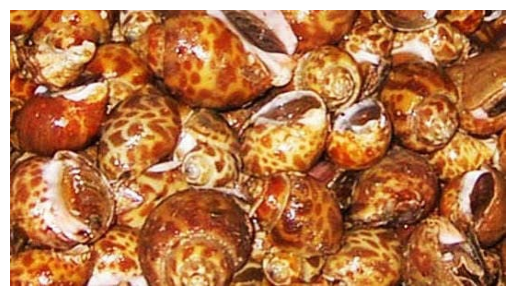

Actual fish:  Jinnaok :Top shell kator
Predicted fish:  Jinnaok :Top shell kator


In [59]:
import torch
import matplotlib.pyplot as plt

# Get one image from the test dataset
sample = test_data[0]

image = sample["image"].convert("RGB")
actual_label = labels[sample["label"]]

# Use the same preprocessing used during testing
pixel_values = sample["pixel_values"].unsqueeze(0)

# Move input to the same device as the model
device = next(model.parameters()).device
pixel_values = pixel_values.to(device)

# Make prediction
model.eval()

with torch.no_grad():
    outputs = model(pixel_values=pixel_values)

# Get predicted class
predicted_id = outputs.logits.argmax(dim=1).item()
predicted_label = labels[predicted_id]

# Display image
plt.imshow(image)
plt.axis("off")
plt.show()

print("Actual fish:", actual_label)
print("Predicted fish:", predicted_label)

In [60]:
# Create a folder to save our trained model
save_path = "/content/fish_species_model"

# Save the fine-tuned model
trainer.save_model(save_path)

# Save the image processor
processor.save_pretrained(save_path)

print("Model and processor saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and processor saved successfully!


In [61]:
!pip install -q huggingface_hub

from huggingface_hub import login

login()

In [ ]:
!pip install -q huggingface_hub

from huggingface_hub import HfApi
from google.colab import userdata

# Get your secret token from Colab
HF_TOKEN = userdata.get("HF_TOKEN")

# Connect to Hugging Face
api = HfApi(token=HF_TOKEN)

# Your model repository
repo_id = "BismaLJ/fish-species-classification"

print("Hugging Face connected successfully!")

Hugging Face connected successfully!


In [62]:
from google.colab import userdata
hf_token = userdata.get('HF_TOKEN')
print(hf_token[:3])

hf_


In [63]:
from google.colab import userdata
from huggingface_hub import HfApi

HF_TOKEN = userdata.get("HF_TOKEN").strip()

print("Token starts correctly:", HF_TOKEN.startswith("hf_"))
print("Token length:", len(HF_TOKEN))

api = HfApi(token=HF_TOKEN)
print(api.whoami()["name"])

Token starts correctly: True
Token length: 37
BismaLJ


In [64]:
from google.colab import userdata
from huggingface_hub import HfApi

HF_TOKEN = userdata.get("HF_TOKEN").strip()

print("Starts with hf_:", HF_TOKEN.startswith("hf_"))
print("Contains non-ASCII characters:", not HF_TOKEN.isascii())

api = HfApi(token=HF_TOKEN)
print("Connected account:", api.whoami()["name"])

Starts with hf_: True
Contains non-ASCII characters: False
Connected account: BismaLJ


In [65]:
api.upload_folder(
    folder_path="/content/fish_species_model",
    repo_id="BismaLJ/fish_species_classification",
    repo_type="model"
)

print("Model uploaded successfully!")

Model uploaded successfully!


In [66]:
from transformers import ViTForImageClassification, ViTImageProcessor

repo_id = "BismaLJ/fish_species_classification"

processor = ViTImageProcessor.from_pretrained(repo_id)
model = ViTForImageClassification.from_pretrained(repo_id)

print("Model loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Labels:", model.config.id2label)

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model loaded successfully!
Number of classes: 25
Labels: {0: ' Jinnaok :Top shell kator', 1: ' Mushko: croaker ', 2: 'Alwahor ', 3: 'Balochi  Gallo\nEnglish spotted catfish', 4: 'Balochi  gore \nEnglish narrow-barred  Spanish mackerel', 5: 'Balochi  madak \nEnglish jinga shrimp', 6: 'Balochi  pittan \nEnglish Arabian banded whipray', 7: 'Balochi  sisi mayyah \nEnglish indian squid', 8: 'Balochi chancho \nEnglish spinycheek grouper', 9: 'Balochi mahpari \nEnglish white spotted spinefoot', 10: 'Balochi saram \nEnglish ltalang queenfish', 11: 'Balochi.   kund \nEnglish.   Giant baracude', 12: 'Balochileejar \nEnglish indian oil sardine', 13: 'Black pamplet', 14: 'Galbath ', 15: 'Kanakawad ', 16: 'Koh prosh ', 17: 'Lutari', 18: 'Pathar ', 19: 'Ping', 20: 'Sawaso ', 21: 'Shurr', 22: 'Soli', 23: 'Surr', 24: 'White pamplet'}
